# 05 — ATT(g,t) Estimation

**Project:** Causal ML for Climate Policy Effectiveness
**Purpose:** Primary carbon-pricing effect estimates via Callaway & Sant'Anna (2021)
doubly-robust staggered-adoption DiD, cross-checked against an independent Sun &
Abraham (2021) event study -- replacing the earlier OLS-vs-DML-vs-Causal-Forest
"comparable estimators" framing, which a journal reviewer showed was structurally
unsound (GroupKFold cross-fitting with one-hot country dummies left held-out
countries with no learnable country-specific control at all).

**Input:** `data/processed/analysis_panel.csv` (WCPD-based carbon-pricing treatment,
see Notebooks 02/04)
**Output:** `outputs/tables/att_gt_overall.csv`, `outputs/tables/event_study_naive.csv`

This notebook presents the naive, headline-looking result. Notebook 06 then
subjects it to formal sensitivity diagnostics.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.did_cs import run_callaway_santanna
from src.event_study import run_event_study, pretrend_test
from src.visualization import set_publication_style, save_figure, COLORS

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
set_publication_style()

In [2]:
panel = pd.read_csv(PROCESSED_DIR / "analysis_panel.csv")
OUTCOME = "log_co2"
TREATMENT = "treat_carbon_price"
COVARIATES = ["population", "gdp_per_capita", "urban_pct"]

panel = panel.dropna(subset=[OUTCOME] + COVARIATES)
print(f"Analysis panel: {panel.shape[0]:,} rows, {panel['iso3'].nunique()} countries, "
      f"{int(panel.loc[panel[TREATMENT]==1,'iso3'].nunique())} ever-treated")
print(f"Years: {panel['year'].min()}-{panel['year'].max()}")

Analysis panel: 6,247 rows, 193 countries, 46 ever-treated
Years: 1990-2022


---
## 5.1 — Callaway & Sant'Anna (2021) Doubly-Robust ATT(g,t)

Primary identification strategy. Never-treated countries throughout as the
comparison group; country-clustered inference.

In [3]:
print("=" * 60)
print("5.1 - Callaway & Sant'Anna ATT(g,t)")
print("=" * 60)

cs_result = run_callaway_santanna(
    panel, outcome_col=OUTCOME, cohort_col="adoption_year",
    unit_col="iso3", time_col="year", covariate_cols=COVARIATES,
    control_group="never_treated",
)

print()
print(f"Overall ATT: {cs_result.overall_att:.4f}  SE={cs_result.overall_se:.4f}  "
      f"95% CI [{cs_result.overall_ci_lower:.4f}, {cs_result.overall_ci_upper:.4f}]  "
      f"p={cs_result.overall_p_value:.4f}")
print(f"Treated units: {cs_result.n_treated_units}  Control units: {cs_result.n_control_units}  "
      f"N={cs_result.n_obs}")

pd.DataFrame([{
    "estimate": cs_result.overall_att, "std_error": cs_result.overall_se,
    "ci_lower": cs_result.overall_ci_lower, "ci_upper": cs_result.overall_ci_upper,
    "p_value": cs_result.overall_p_value, "n_treated_units": cs_result.n_treated_units,
    "n_control_units": cs_result.n_control_units, "n_obs": cs_result.n_obs,
}]).to_csv(TABLE_DIR / "att_gt_overall.csv", index=False)
cs_result.event_study.to_csv(TABLE_DIR / "att_gt_event_study.csv")
print()
print("Saved: att_gt_overall.csv, att_gt_event_study.csv")

5.1 - Callaway & Sant'Anna ATT(g,t)


Computing ATTgt [workers=1]     0%|                    | 0/576 [00:00<?, ?it/s]

Computing ATTgt [workers=1]     3%|▌                   | 16/576 [00:00<00:03, 156.42it/s]

Computing ATTgt [workers=1]     6%|█▏                  | 34/576 [00:00<00:03, 161.93it/s]

Computing ATTgt [workers=1]     9%|█▊                  | 53/576 [00:00<00:03, 170.03it/s]

...

Computing ATTgt [workers=1]    92%|██████████████████▎ | 529/576 [00:02<00:00, 177.18it/s]

Computing ATTgt [workers=1]    95%|██████████████████▉ | 547/576 [00:03<00:00, 163.49it/s]

Computing ATTgt [workers=1]    98%|███████████████████▌| 564/576 [00:03<00:00, 157.56it/s]

Computing ATTgt [workers=1]   100%|████████████████████| 576/576 [00:03<00:00, 173.76it/s]


Overall ATT: -0.2887  SE=0.1061  95% CI [-0.4966, -0.0807]  p=0.0065
Treated units: 46  Control units: 147  N=6247

Saved: att_gt_overall.csv, att_gt_event_study.csv


---
## 5.2 — Sun & Abraham (2021) Event Study Cross-Check

An independent staggered-adoption design with a different estimation approach
(cohort x event-time interaction weighting vs. C&S's doubly-robust ATT(g,t)).
If both agree, that is a structurally sound robustness story -- no
cross-fitting-vs-fixed-effects mismatch to defend, unlike the project's prior
OLS/DML/Causal-Forest comparison.

In [4]:
print("=" * 60)
print("5.2 - Sun-Abraham Event Study (naive specification)")
print("=" * 60)

es_naive = run_event_study(
    panel, treatment_col=TREATMENT, outcome_col=OUTCOME,
    unit_col="iso3", time_col="year", covariate_cols=COVARIATES,
    window=(-5, 5),
)
print(es_naive.to_string(index=False))
print()
print("Pre-trend test:", pretrend_test(es_naive))

es_naive.to_csv(TABLE_DIR / "event_study_naive.csv", index=False)
print()
print("Saved: event_study_naive.csv")

5.2 - Sun-Abraham Event Study (naive specification)


 event_time  estimate  std_error  ci_lower  ci_upper      p_value  n_cohorts
         -5  0.209003   0.038452  0.133639  0.284367 5.465400e-08         16
         -4  0.059433   0.013531  0.032913  0.085954 1.121173e-05         16
         -3  0.046277   0.010624  0.025455  0.067099 1.323982e-05         16
         -2  0.012296   0.007336 -0.002082  0.026674 9.369907e-02         17
         -1  0.000000   0.000000  0.000000  0.000000          NaN         18
          0 -0.012287   0.005826 -0.023705 -0.000868 3.495411e-02         18
          1 -0.036996   0.008829 -0.054302 -0.019691 2.788036e-05         18
          2 -0.064774   0.012357 -0.088993 -0.040556 1.587933e-07         17
          3 -0.102252   0.015090 -0.131828 -0.072676 1.234717e-11         16
          4 -0.158555   0.017279 -0.192421 -0.124689 4.463774e-20         15
          5 -0.483152   0.039659 -0.560882 -0.405422 3.844129e-34         14

Pre-trend test: {'n_pretrend_periods': 4, 'n_significant': 3, 'all_insignif

---
## 5.3 — The Naive Picture

On the surface, the two independent staggered-adoption designs agree: both find
a sizeable, significant negative carbon-pricing effect, growing over the
post-treatment horizon. This LOOKS like exactly the clean, structurally sound
robustness story the project's rebuild was aiming for.

Notebook 06 shows why this naive agreement is not the end of the story.

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig_naive_agreement.png


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\fig_naive_agreement.pdf


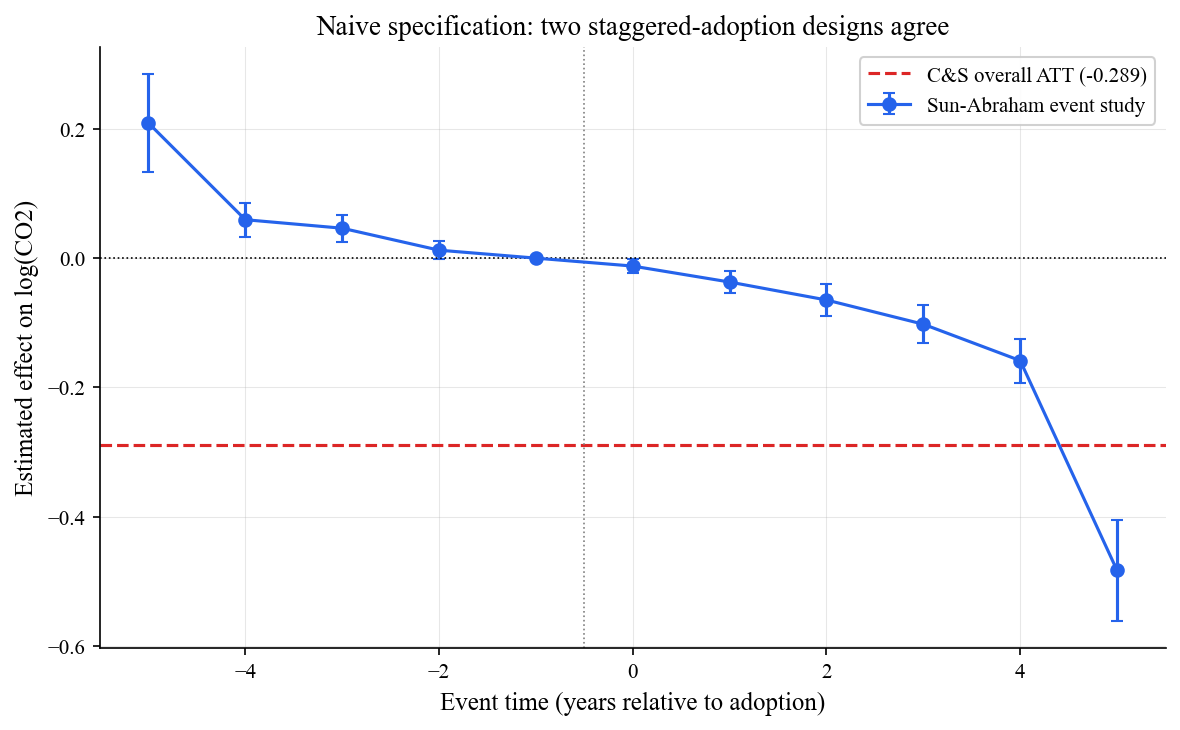


Proceed to Notebook 06: Sensitivity Diagnostics


In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(es_naive["event_time"], es_naive["estimate"],
            yerr=[es_naive["estimate"] - es_naive["ci_lower"], es_naive["ci_upper"] - es_naive["estimate"]],
            fmt="o-", capsize=3, color=COLORS["primary"], label="Sun-Abraham event study")
ax.axhline(cs_result.overall_att, color=COLORS["danger"], linestyle="--",
           label=f"C&S overall ATT ({cs_result.overall_att:.3f})")
ax.axhline(0, color="black", linestyle=":", linewidth=0.8)
ax.axvline(-0.5, color="gray", linestyle=":", linewidth=0.8)
ax.set_xlabel("Event time (years relative to adoption)")
ax.set_ylabel("Estimated effect on log(CO2)")
ax.set_title("Naive specification: two staggered-adoption designs agree")
ax.legend()
plt.tight_layout()
save_figure(fig, "fig_naive_agreement")
plt.show()

print()
print("Proceed to Notebook 06: Sensitivity Diagnostics")